# 2. OCR from bubble crops

Load bubbles.json, run PaddleOCR 3 on each crop, and save text plus line confidences. Set LANGUAGE to match the page. OCR ordering follows PaddleOCR within each bubble.

Run cells top to bottom, then inspect the displayed output before continuing.

Use the **.venvOCR (1pageTest OCR)** kernel. It points to the existing Python 3.11 environment at `C:/Users/ESHAAN/BYTE/Applied-Task/MultiModelSystem/.venvOCR`, with PaddleOCR and PaddlePaddle GPU already installed.


In [6]:
import sys
print(sys.executable)

c:\Users\ESHAAN\BYTE\Applied-Task\MultiModelSystem\.venvOCR\Scripts\python.exe


In [7]:
from pathlib import Path
import hashlib
import json
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

# Works when the kernel starts in the project root or this stage folder.
ROOT = Path.cwd().resolve()
if not (ROOT / "models.json").exists():
    ROOT = ROOT.parent
if not (ROOT / "models.json").exists():
    raise FileNotFoundError("Start the kernel in 1pageTest or a stage folder.")
SEQUENCE_ID = "seq_71033fec4de494fc"
PAGE_NUMBER = 2
# Dataset page filenames are zero-padded: page 1 is 01.png.
PAGE = ROOT / "TaskData/development/images" / SEQUENCE_ID / f"{PAGE_NUMBER:02d}.png"
OUT = ROOT / "data/intermediate"
OUT.mkdir(parents=True, exist_ok=True)
MODELS = json.loads((ROOT / "models.json").read_text(encoding="utf-8"))
if not PAGE.is_file():
    raise FileNotFoundError(f"Put your manga page at {PAGE}, or edit PAGE.")
page = Image.open(PAGE).convert("RGB")
PAGE_INFO = {"name": PAGE.name, "sha256": hashlib.sha256(PAGE.read_bytes()).hexdigest(),
             "width": page.width, "height": page.height}

def save_stage(name, records):
    path = OUT / name
    path.write_text(json.dumps({"page": PAGE_INFO, "records": records},
                               ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"Saved {path}")

def load_stage(name):
    path = OUT / name
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}; run the preceding stage first.")
    payload = json.loads(path.read_text(encoding="utf-8"))
    if payload["page"] != PAGE_INFO:
        raise ValueError(f"{name} belongs to a different page. Rerun the earlier stages.")
    return payload["records"]


In [8]:
import numpy as np
from paddleocr import PaddleOCR

bubbles = load_stage("bubbles.json")
LANGUAGE = "en"  # For Japanese pages use "japan".
ocr = PaddleOCR(lang=LANGUAGE, use_doc_orientation_classify=False,
                use_doc_unwarping=False, use_textline_orientation=False)
CROPS = OUT / "bubble_crops"
CROPS.mkdir(exist_ok=True)


Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\ESHAAN\.paddlex\official_models\PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\ESHAAN\.paddlex\official_models\PP-OCRv6_medium_rec`.


Saved C:\Users\ESHAAN\BYTE\Applied-Task\1pageTest\data\intermediate\ocr.json
B1: HE'LL TELL YOU "I MAY BE VENOMOUS, BUT I'VE GOT A GREAT POISON- ALITY"!


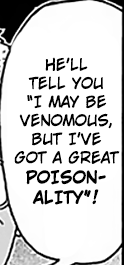

B2: GET IT?


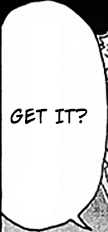

B3: IT'S DANGEROUS EVEN IF YOU ONLY GET A SMALL BITE.


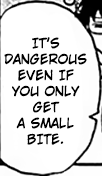

B4: THAT'S BECAUSE VIPERS ARE VENOMOUS!


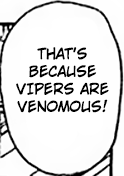

B5: I'M SERIOUS!


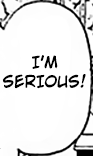

B6: IF YOU SEE A VIPER, SE TRY ASKING IF HE'S VENOMOUS!


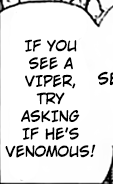

B7: THE OTHER DAY, I WAS WALKING THROUGH THE FOREST WHEN A VIPER SUDDENLY JUMPED OUT IN FRONT OF ME.


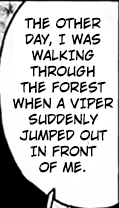

B8: AND WHAT DO YOU THINK THE SNAKE DID NEXT?


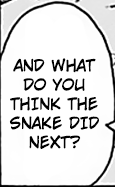

B9: THERE'S A LOT OF VIPERS ON THE ISLAND.


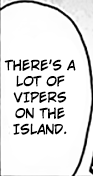

B10: FANGFULLY, IT MOVED OUT OF THE WAY!


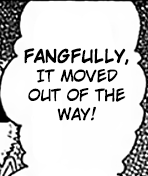

B11: OH, THAT'S RIGHT~


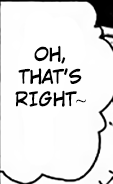

B12: GET IT?


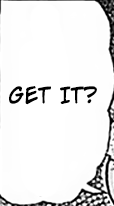

B13: WE DON'T ACTUALLY HAVE A LOT OF TIME...


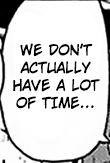

B14: IT'S NOT JUST KAIDOU, TODAY HAS BEEN FULL OF ANNOYING PEOPLE.


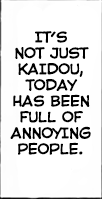

B15: I DIDN'T EVEN HAVE TO ASP!


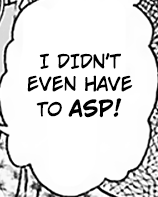

B16: HAHAHA


B17: [no text recognized]


B18: OH! IS THAT THE MON- GOOSE!?


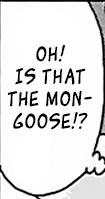

B19: LET'S START THE SHOW THEN...


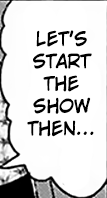

B20: THIS GUY JUST WON'T STOP.


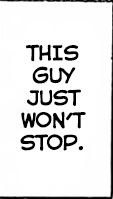

In [9]:
ocr_results = []
for bubble in bubbles:
    crop = page.crop(bubble["box"])
    crop.save(CROPS / f"{bubble['bubble_id']}.png")
    lines = []
    for result in ocr.predict(input=np.asarray(crop)):
        for text, score in zip(result["rec_texts"], result["rec_scores"]):
            lines.append({"text": str(text), "confidence": float(score)})
    ocr_results.append({"bubble_id": bubble["bubble_id"], "box": bubble["box"],
                        "text": " ".join(line["text"] for line in lines), "lines": lines})
save_stage("ocr.json", ocr_results)
for record in ocr_results:
    print(f"{record['bubble_id']}: {record['text'] or '[no text recognized]'}")
    display(Image.open(CROPS / f"{record['bubble_id']}.png"))


## Clean bubbles after OCR

Keep the larger box when overlapping bubbles have the same non-empty OCR text. Raw bubble/OCR files and crops are preserved.

For empty OCR, choose either option in the next cell:
- Set DELETE_EMPTY_BUBBLES=True to remove all bubbles whose OCR text is empty or whitespace.
- Keep it False and list individual IDs in EMPTY_BUBBLES_TO_DELETE to remove only those empty bubbles.

Both options default to keeping empty bubbles. A selected bubble must actually have empty OCR text. Removal affects bubbles_clean.json and ocr_clean.json together; original IDs are not renumbered. Non-empty bubbles with weak or missing GT matches remain.

After changing the options, rerun this cleanup cell and the GT-label cell, then regenerate downstream annotations/reading order as needed. No existing result files are changed just by editing this notebook.


In [13]:
# Optional empty-text deletion, followed by overlapping duplicate cleanup.
DELETE_EMPTY_BUBBLES = True  # True removes every empty OCR bubble.
EMPTY_BUBBLES_TO_DELETE = []  # Or select individual empty IDs, e.g. ["B16"].
def normalize_text(text):
    return " ".join(text.upper().split())

def box_area(box):
    x1, y1, x2, y2 = box
    return max(0, x2 - x1) * max(0, y2 - y1)

ocr_by_id = {record["bubble_id"]: record for record in ocr_results}
kept_bubbles = []
empty_ids = [r["bubble_id"] for r in ocr_results if not r["text"].strip()]
invalid_ids = set(EMPTY_BUBBLES_TO_DELETE) - set(empty_ids)
if invalid_ids:
    raise ValueError(f"These IDs are missing or have non-empty OCR: {sorted(invalid_ids)}")
removed_empty_ids = [bubble_id for bubble_id in empty_ids
                     if DELETE_EMPTY_BUBBLES or bubble_id in EMPTY_BUBBLES_TO_DELETE]
removed_ids = removed_empty_ids.copy()
MIN_OVERLAP = 0.80

# Check larger boxes first so a duplicate inner box is removed.
for bubble in sorted(bubbles, key=lambda b: box_area(b["box"]), reverse=True):
    if bubble["bubble_id"] in removed_empty_ids:
        print(f"Remove {bubble['bubble_id']}: no OCR text found")
        continue
    text = normalize_text(ocr_by_id[bubble["bubble_id"]]["text"])
    duplicate = False
    for kept in kept_bubbles:
        kept_text = normalize_text(ocr_by_id[kept["bubble_id"]]["text"])
        if not text or text != kept_text:
            continue
        x1, y1, x2, y2 = bubble["box"]
        kx1, ky1, kx2, ky2 = kept["box"]
        intersection = max(0, min(x2, kx2) - max(x1, kx1)) * max(0, min(y2, ky2) - max(y1, ky1))
        smaller_area = min(box_area(bubble["box"]), box_area(kept["box"]))
        if smaller_area > 0 and intersection / smaller_area >= MIN_OVERLAP:
            duplicate = True
            print(f"Remove {bubble['bubble_id']}: duplicate of {kept['bubble_id']}")
            break
    if duplicate:
        removed_ids.append(bubble["bubble_id"])
    else:
        kept_bubbles.append(bubble)

# Keep the original order/IDs. Non-empty unmatched OCR bubbles stay.
clean_bubbles = [b for b in bubbles if b["bubble_id"] not in removed_ids]
clean_ocr = [r for r in ocr_results if r["bubble_id"] not in removed_ids]
save_stage("bubbles_clean.json", clean_bubbles)
save_stage("ocr_clean.json", clean_ocr)
print(f"Kept {len(clean_bubbles)} bubbles; removed {len(removed_empty_ids)} empty bubbles "
      f"and {len(removed_ids) - len(removed_empty_ids)} duplicates.")


Remove B17: no OCR text found
Saved C:\Users\ESHAAN\BYTE\Applied-Task\1pageTest\data\intermediate\bubbles_clean.json
Saved C:\Users\ESHAAN\BYTE\Applied-Task\1pageTest\data\intermediate\ocr_clean.json
Kept 19 bubbles; removed 1 empty bubbles and 0 duplicates.


## Match each retained bubble to one GT speaker

Read this sequence and page from `TaskData/development/labels.jsonl`. Choose one highest-scoring transcript match, accepting scores of at least 80. Exact matches score 100. A tie uses the first GT entry. No multiple-match or split-transcript handling for now. Unmatched bubbles remain with `speaker=None`; this does not mean `UNKNOWN`. These GT labels are saved separately and are not passed into the inference prompt.


In [14]:
from difflib import SequenceMatcher

LABELS = ROOT / "TaskData/development/labels.jsonl"
sequence = None
with LABELS.open(encoding="utf-8") as file:
    for line in file:
        if not line.strip():
            continue
        entry = json.loads(line)
        if entry["sequence_id"] == SEQUENCE_ID:
            sequence = entry
            break
if sequence is None:
    raise ValueError(f"No GT for sequence {SEQUENCE_ID}")
gt_dialogue = sequence["pages"][PAGE_NUMBER - 1]
if not gt_dialogue:
    raise ValueError("This page has no GT dialogue.")

MIN_MATCH_SCORE = 80.0  # Raise this for stricter matches.
bubble_gt_labels = []
for record in clean_ocr:
    text = normalize_text(record["text"])
    best_gt = None
    best_score = -1.0
    for gt in gt_dialogue:
        score = 100 * SequenceMatcher(None, text, normalize_text(gt["text"])).ratio() if text else 0.0
        if score > best_score:
            best_gt = gt
            best_score = score
    speaker = best_gt["speaker"] if text and best_score >= MIN_MATCH_SCORE else None
    label = {
        "bubble_id": record["bubble_id"],
        "text": record["text"],
        "gt_text": best_gt["text"] if speaker is not None else None,
        "speaker": speaker,
        "match_score": round(best_score, 1),
    }
    bubble_gt_labels.append(label)
    print(f"{label['bubble_id']} -> {speaker} ({label['match_score']}): {record['text']}")

# No bubble is excluded because its GT match is weak or missing.
# GT speaker names are identities, not the detector's C appearance IDs.
save_stage("bubble_gt_labels.json", {
    "sequence_id": SEQUENCE_ID,
    "page_number": PAGE_NUMBER,
    "bubbles": bubble_gt_labels,
})


B1 -> character3 (99.3): HE'LL TELL YOU "I MAY BE VENOMOUS, BUT I'VE GOT A GREAT POISON- ALITY"!
B2 -> character3 (100.0): GET IT?
B3 -> character3 (100.0): IT'S DANGEROUS EVEN IF YOU ONLY GET A SMALL BITE.
B4 -> character3 (100.0): THAT'S BECAUSE VIPERS ARE VENOMOUS!
B5 -> character3 (100.0): I'M SERIOUS!
B6 -> character3 (97.0): IF YOU SEE A VIPER, SE TRY ASKING IF HE'S VENOMOUS!
B7 -> character3 (100.0): THE OTHER DAY, I WAS WALKING THROUGH THE FOREST WHEN A VIPER SUDDENLY JUMPED OUT IN FRONT OF ME.
B8 -> character3 (100.0): AND WHAT DO YOU THINK THE SNAKE DID NEXT?
B9 -> character3 (100.0): THERE'S A LOT OF VIPERS ON THE ISLAND.
B10 -> character3 (100.0): FANGFULLY, IT MOVED OUT OF THE WAY!
B11 -> character3 (100.0): OH, THAT'S RIGHT~
B12 -> character3 (100.0): GET IT?
B13 -> character1 (100.0): WE DON'T ACTUALLY HAVE A LOT OF TIME...
B14 -> character2 (100.0): IT'S NOT JUST KAIDOU, TODAY HAS BEEN FULL OF ANNOYING PEOPLE.
B15 -> character3 (100.0): I DIDN'T EVEN HAVE TO ASP!
B16 ->